In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [23]:
dataset_path = Path.cwd() / "Dataset" /"ncr_ride_bookings.csv"

dataset_path

WindowsPath('c:/LocalFiles/program/Sem5/Machine Learning Lab/mini-project/Dataset/ncr_ride_bookings.csv')

In [24]:
df = pd.read_csv(dataset_path)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (150000, 21)


,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  object 
 1   Time                               150000 non-null  object 
 2   Booking ID                         150000 non-null  object 
 3   Booking Status                     150000 non-null  object 
 4   Customer ID                        150000 non-null  object 
 5   Vehicle Type                       150000 non-null  object 
 6   Pickup Location                    150000 non-null  object 
 7   Drop Location                      150000 non-null  object 
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for cancelling by Customer  1050

In [26]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
Date                                      0
Time                                      0
Booking ID                                0
Booking Status                            0
Customer ID                               0
Vehicle Type                              0
Pickup Location                           0
Drop Location                             0
Avg VTAT                              10500
Avg CTAT                              48000
Cancelled Rides by Customer          139500
Reason for cancelling by Customer    139500
Cancelled Rides by Driver            123000
Driver Cancellation Reason           123000
Incomplete Rides                     141000
Incomplete Rides Reason              141000
Booking Value                         48000
Ride Distance                         48000
Driver Ratings                        57000
Customer Rating                       57000
Payment Method                        48000
dtype: int64

Total Missing Values: 1123500

Duplicate Rows:

In [27]:
print("Date Column:")
print(df["Date"].head(10))

print("\nTime Column:")
print(df["Time"].head(10))

print("\nDate Data Type:", df["Date"].dtype)
print("Time Data Type:", df["Time"].dtype)

Date Column:
0    2024-03-23
1    2024-11-29
2    2024-08-23
3    2024-10-21
4    2024-09-16
5    2024-02-06
6    2024-06-17
7    2024-03-19
8    2024-09-14
9    2024-12-16
Name: Date, dtype: object

Time Column:
0    12:29:38
1    18:01:39
2    08:56:10
3    17:17:25
4    22:08:00
5    09:44:56
6    15:45:58
7    17:37:37
8    12:49:09
9    19:06:48
Name: Time, dtype: object

Date Data Type: object
Time Data Type: object


In [28]:
print(df["Booking Status"].value_counts(dropna=False))

Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64


In [29]:
categorical_columns = [
    "Vehicle Type",
    "Booking Status",
    "Payment Method"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


Vehicle Type
Vehicle Type
Auto             37419
Go Mini          29806
Go Sedan         27141
Bike             22517
Premier Sedan    18111
eBike            10557
Uber XL           4449
Name: count, dtype: int64

Booking Status
Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64

Payment Method
Payment Method
NaN            48000
UPI            45909
Cash           25367
Uber Wallet    12276
Credit Card    10209
Debit Card      8239
Name: count, dtype: int64


In [30]:
df["Booking Timestamp"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    errors="coerce"
)

print(df[["Date", "Time", "Booking Timestamp"]].head(10))

         Date      Time   Booking Timestamp
0  2024-03-23  12:29:38 2024-03-23 12:29:38
1  2024-11-29  18:01:39 2024-11-29 18:01:39
2  2024-08-23  08:56:10 2024-08-23 08:56:10
3  2024-10-21  17:17:25 2024-10-21 17:17:25
4  2024-09-16  22:08:00 2024-09-16 22:08:00
5  2024-02-06  09:44:56 2024-02-06 09:44:56
6  2024-06-17  15:45:58 2024-06-17 15:45:58
7  2024-03-19  17:37:37 2024-03-19 17:37:37
8  2024-09-14  12:49:09 2024-09-14 12:49:09
9  2024-12-16  19:06:48 2024-12-16 19:06:48


In [31]:
print("Earliest Booking:", df["Booking Timestamp"].min())
print("Latest Booking:", df["Booking Timestamp"].max())

print("Unique Booking Dates:",
      df["Booking Timestamp"].dt.date.nunique())

print("Invalid Timestamps:",
      df["Booking Timestamp"].isna().sum())

print("Unique Booking IDs:",
      df["Booking ID"].nunique())

Earliest Booking: 2024-01-01 00:19:34
Latest Booking: 2024-12-30 23:36:11
Unique Booking Dates: 365
Invalid Timestamps: 0
Unique Booking IDs: 148767


In [32]:
df["Hour"] = df["Booking Timestamp"].dt.hour

df["DayOfWeek"] = df["Booking Timestamp"].dt.dayofweek

print("Bookings per Hour:")
print(df["Hour"].value_counts().sort_index())

print("\nBookings per Day:")
print(df["DayOfWeek"].value_counts().sort_index())

Bookings per Hour:
Hour
0      1373
1      1360
2      1339
3      1383
4      1321
5      2786
6      4160
7      5450
8      6861
9      8234
10     9577
11     8390
12     7006
13     5470
14     7031
15     8202
16     9633
17    11044
18    12397
19    11047
20     9630
21     8103
22     5441
23     2762
Name: count, dtype: int64

Bookings per Day:
DayOfWeek
0    21644
1    21391
2    21413
3    21215
4    21397
5    21542
6    21398
Name: count, dtype: int64


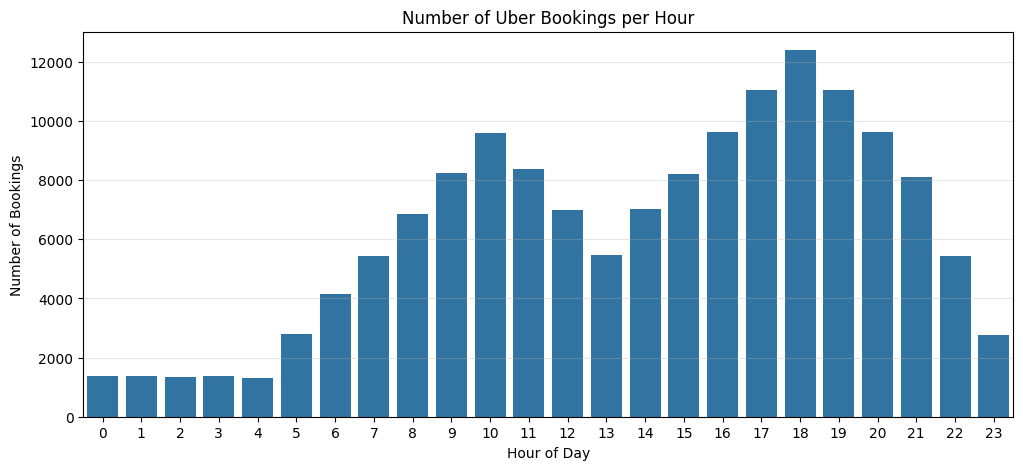

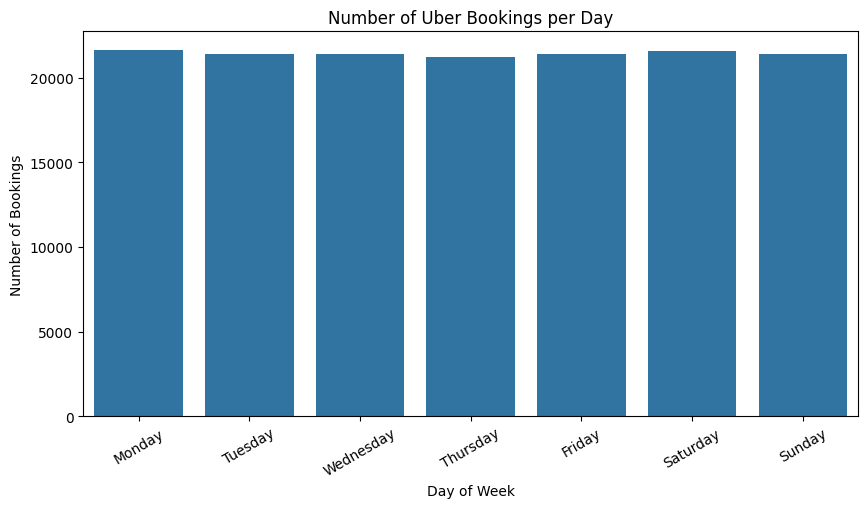

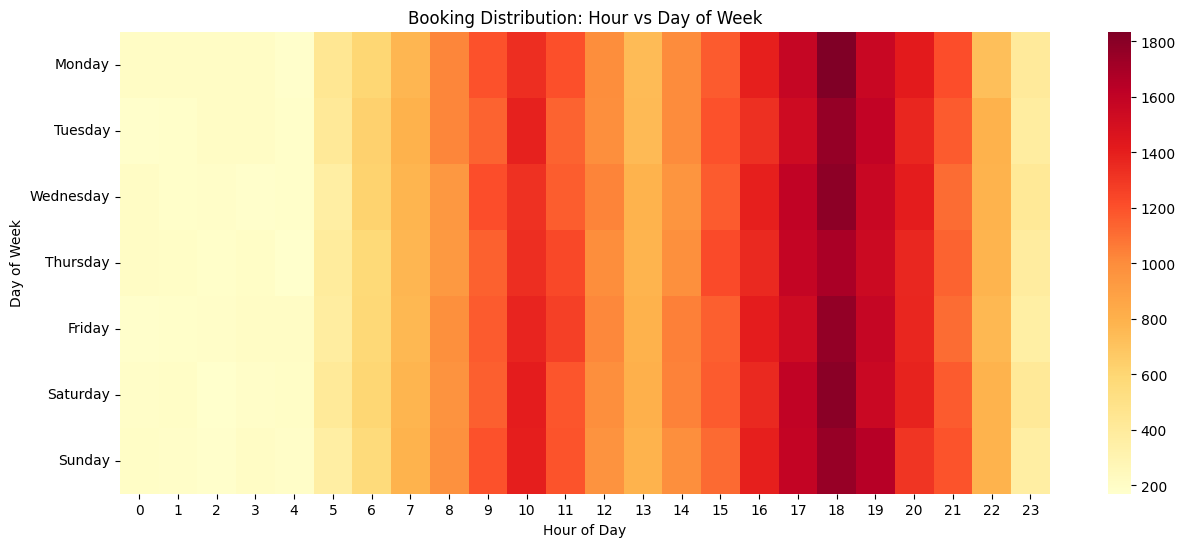

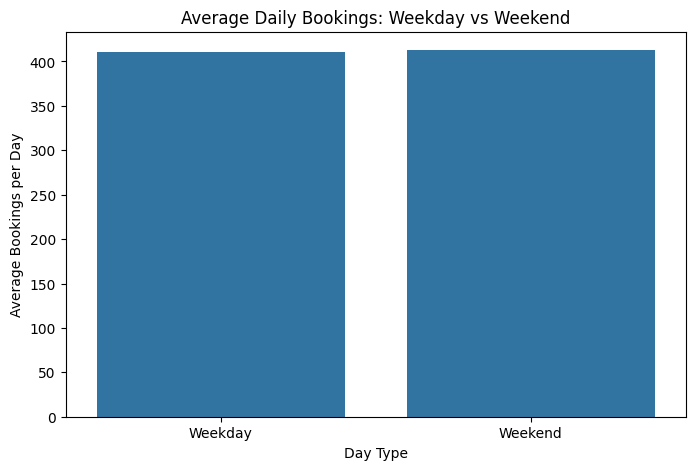

Average daily bookings:
Day_Type
Weekday    410.191571
Weekend    412.884615
dtype: float64


In [33]:

# 1. Bookings per hour
hour_counts = df["Hour"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.barplot(x=hour_counts.index, y=hour_counts.values)
plt.title("Number of Uber Bookings per Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Bookings")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.show()


# 2. Bookings per day of week
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

day_counts = df["DayOfWeek"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=day_names, y=day_counts.values)
plt.title("Number of Uber Bookings per Day")
plt.xlabel("Day of Week")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=30)
plt.show()


# 3. Hour vs Day of Week heatmap
heatmap_data = df.pivot_table(
    index="DayOfWeek",
    columns="Hour",
    values="Booking ID",
    aggfunc="count"
)

heatmap_data.index = day_names

plt.figure(figsize=(15, 6))
sns.heatmap(heatmap_data, cmap="YlOrRd")
plt.title("Booking Distribution: Hour vs Day of Week")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.show()


# 4. Weekday vs Weekend comparison
df["Day_Type"] = np.where(df["DayOfWeek"] < 5, "Weekday", "Weekend")

day_type_counts = df["Day_Type"].value_counts()

# Average bookings per calendar day
daily_counts = df.groupby(
    [df["Booking Timestamp"].dt.date, "Day_Type"]
).size()

average_daily = daily_counts.groupby("Day_Type").mean()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=average_daily.index,
    y=average_daily.values
)
plt.title("Average Daily Bookings: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Bookings per Day")
plt.show()

print("Average daily bookings:")
print(average_daily)


In [34]:

df["Hour_Sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
df["Hour_Cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

X = df[["Hour_Sin", "Hour_Cos"]]

print(X.head())
print(X.shape)

       Hour_Sin      Hour_Cos
0  1.224647e-16 -1.000000e+00
1 -1.000000e+00 -1.836970e-16
2  8.660254e-01 -5.000000e-01
3 -9.659258e-01 -2.588190e-01
4 -5.000000e-01  8.660254e-01
(150000, 2)


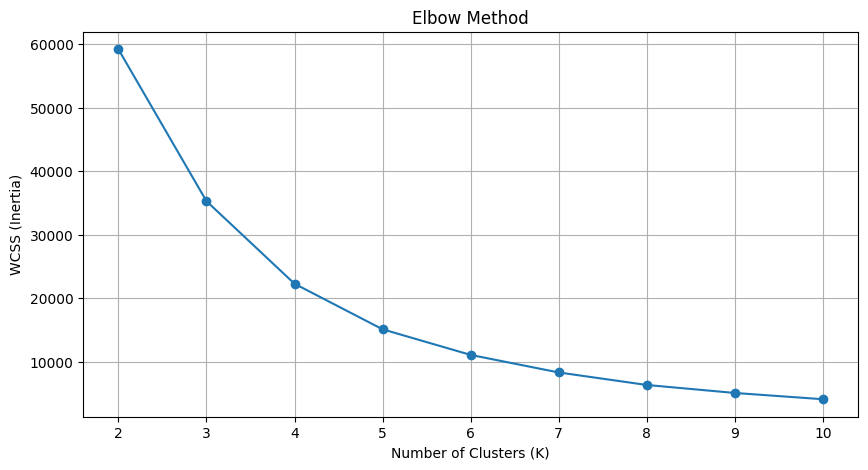

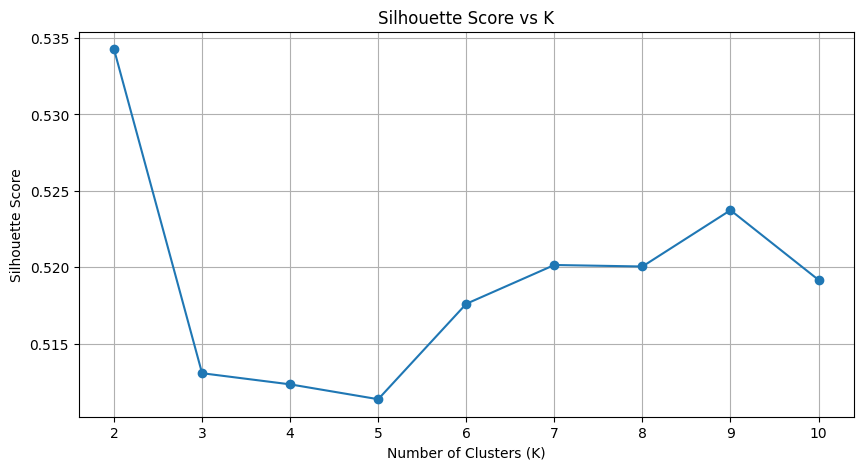

Silhouette Scores:
K=2: 0.5343
K=3: 0.5131
K=4: 0.5123
K=5: 0.5114
K=6: 0.5176
K=7: 0.5202
K=8: 0.5201
K=9: 0.5237
K=10: 0.5192


In [42]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df["Hour_Fraction"] = (
    df["Booking Timestamp"].dt.hour
    + df["Booking Timestamp"].dt.minute / 60
    + df["Booking Timestamp"].dt.second / 3600
)

df["Hour_Sin"] = np.sin(2 * np.pi * df["Hour_Fraction"] / 24)
df["Hour_Cos"] = np.cos(2 * np.pi * df["Hour_Fraction"] / 24)

X = df[["Hour_Sin", "Hour_Cos"]]

inertia = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    inertia.append(model.inertia_)

    score = silhouette_score(
        X, labels,
        sample_size=10000,
        random_state=42
    )

    silhouette_scores.append(score)

# Elbow plot
plt.figure(figsize=(10, 5))
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid()
plt.show()

# Silhouette plot
plt.figure(figsize=(10, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.xticks(list(k_values))
plt.grid()
plt.show()

print("Silhouette Scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"K={k}: {score:.4f}")


In [43]:
optimal_k = 4  #K selected from the plots

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X)

print(df["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0    47171
1    38673
2    23540
3    40616
Name: count, dtype: int64


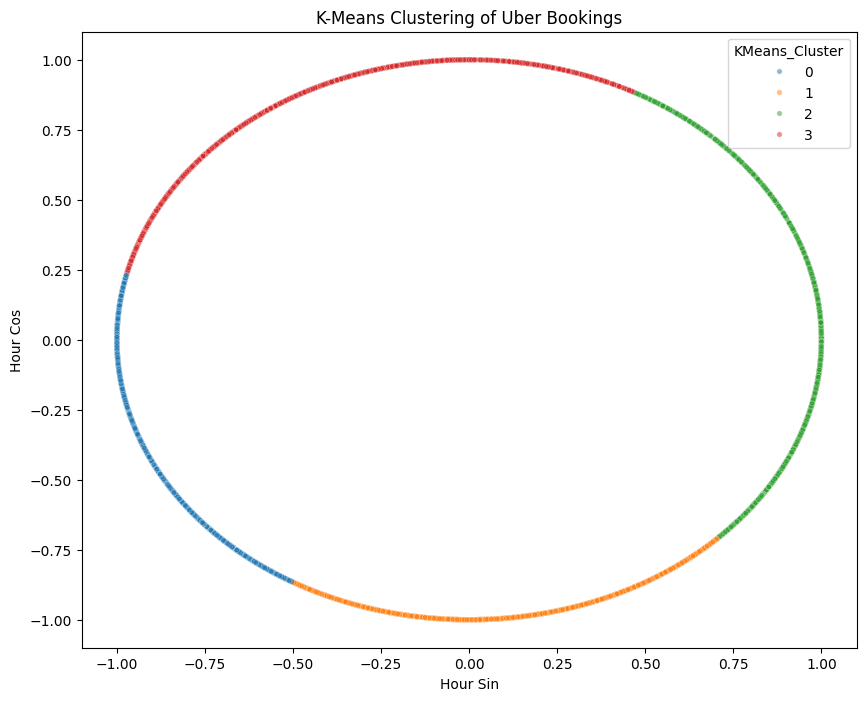

In [44]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df.sample(15000, random_state=42),
    x="Hour_Sin",
    y="Hour_Cos",
    hue="KMeans_Cluster",
    palette="tab10",
    alpha=0.5,
    s=15
)

plt.title("K-Means Clustering of Uber Bookings")
plt.xlabel("Hour Sin")
plt.ylabel("Hour Cos")
plt.show()

In [45]:
cluster_analysis = df.groupby("KMeans_Cluster").agg(
    Bookings=("Booking ID", "count"),
    Average_Hour=("Hour", "mean"),
    Minimum_Hour=("Hour", "min"),
    Maximum_Hour=("Hour", "max")
)

print(cluster_analysis)

                Bookings  Average_Hour  Minimum_Hour  Maximum_Hour
KMeans_Cluster                                                    
0                  47171     16.244006            14            18
1                  38673     10.797507             9            14
2                  23540      6.148131             1             9
3                  40616     19.119854             0            23


Text(0.5, 0, 'Hour')

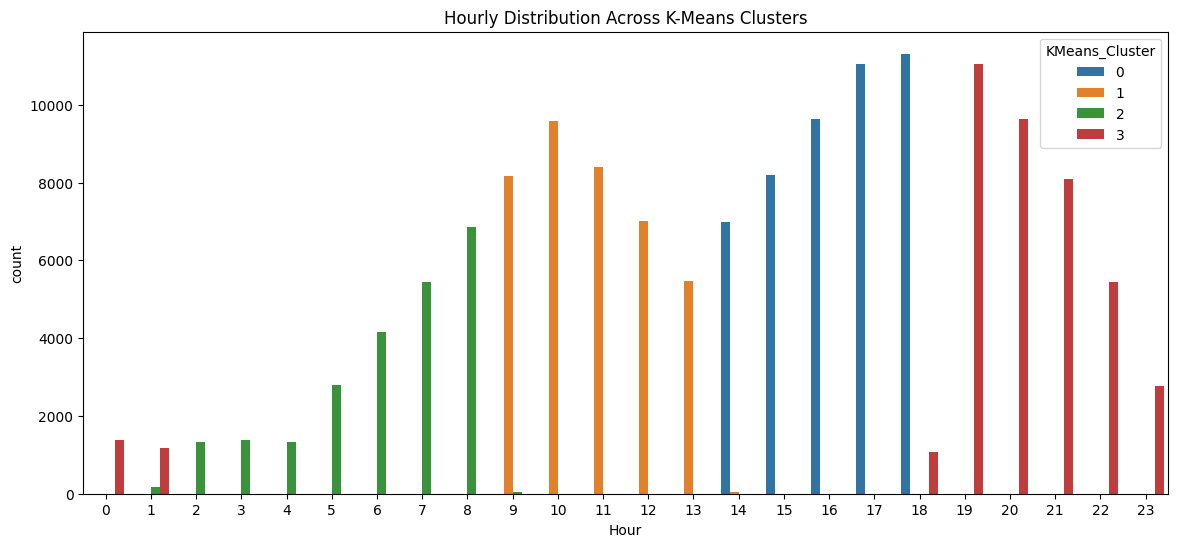

In [46]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    x="Hour",
    hue="KMeans_Cluster",
    palette="tab10"
)

plt.title("Hourly Distribution Across K-Means Clusters")
plt.xlabel("Hour")

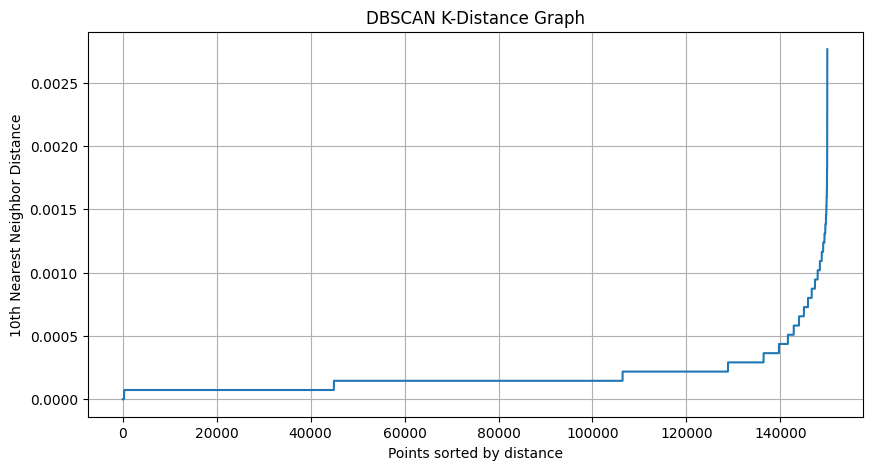

In [47]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=10, algorithm="kd_tree")
neighbors_fit = neighbors.fit(X)

distances, indices = neighbors_fit.kneighbors(X)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.xlabel("Points sorted by distance")
plt.ylabel("10th Nearest Neighbor Distance")
plt.title("DBSCAN K-Distance Graph")
plt.grid()
plt.show()

In [48]:
from sklearn.cluster import DBSCAN

eps_values = [0.0002, 0.0003, 0.0004, 0.0005]

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=10,
        n_jobs=-1
    )

    labels = model.fit_predict(X)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = np.sum(labels == -1)

    print(f"\neps = {eps}")
    print("Number of clusters:", n_clusters)
    print("Noise points:", noise)
    print("Noise percentage:", round(noise / len(X) * 100, 2), "%")


eps = 0.0002
Number of clusters: 2846
Noise points: 26197
Noise percentage: 17.46 %

eps = 0.0003
Number of clusters: 568
Noise points: 9712
Noise percentage: 6.47 %

eps = 0.0004
Number of clusters: 371
Noise points: 7747
Noise percentage: 5.16 %

eps = 0.0005
Number of clusters: 301
Noise points: 6328
Noise percentage: 4.22 %


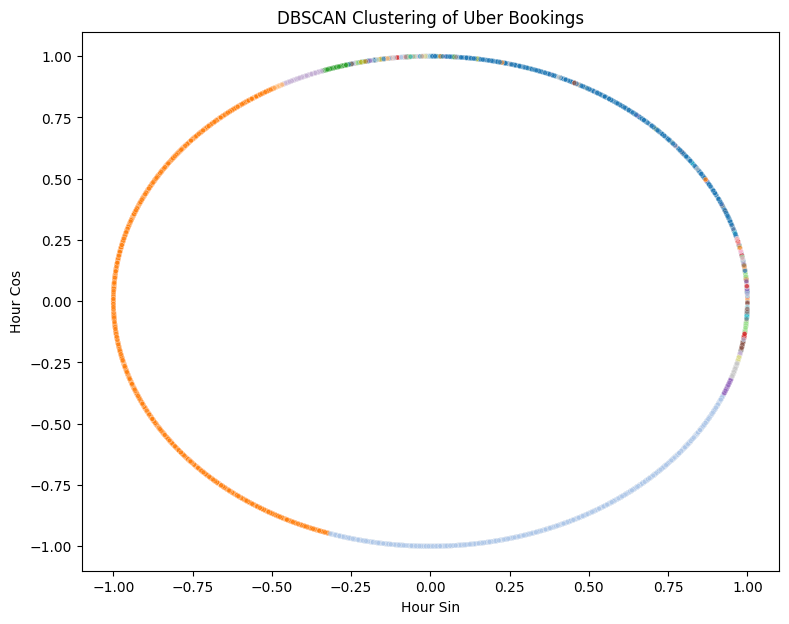

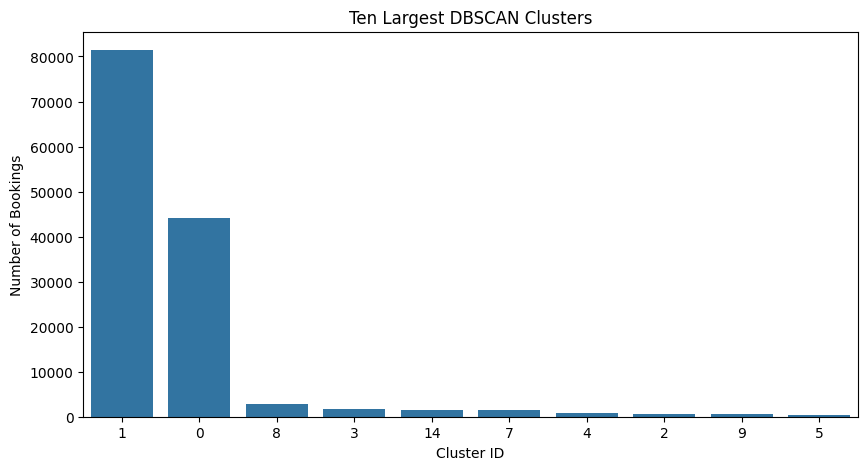

Final DBSCAN Results:
DBSCAN_Cluster
 1     81431
 0     44228
-1      6328
 8      2912
 3      1770
 14     1409
 7      1385
 4       890
 2       594
 9       588
Name: count, dtype: int64


In [49]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.0005, min_samples=10, n_jobs=-1)

df["DBSCAN_Cluster"] = dbscan.fit_predict(X)

# Visualization 1: Clustered points vs noise
plot_df = df.sample(15000, random_state=42)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=plot_df,
    x="Hour_Sin",
    y="Hour_Cos",
    hue="DBSCAN_Cluster",
    palette="tab20",
    alpha=0.6,
    s=12,
    legend=False
)

plt.title("DBSCAN Clustering of Uber Bookings")
plt.xlabel("Hour Sin")
plt.ylabel("Hour Cos")
plt.show()


# Visualization 2: Ten largest clusters
cluster_sizes = (
    df[df["DBSCAN_Cluster"] != -1]["DBSCAN_Cluster"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=cluster_sizes.index.astype(str),
    y=cluster_sizes.values
)

plt.title("Ten Largest DBSCAN Clusters")
plt.xlabel("Cluster ID")
plt.ylabel("Number of Bookings")
plt.show()

print("Final DBSCAN Results:")
print(df["DBSCAN_Cluster"].value_counts().head(10))


In [51]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

#a random sample
sample = df.sample(n=3000, random_state=42).copy()

X_sample = sample[["Hour_Sin", "Hour_Cos"]]

# Apply Agglomerative Clustering
agg = AgglomerativeClustering(n_clusters=4, linkage="ward")

sample["Agg_Cluster"] = agg.fit_predict(X_sample)

print("Cluster Distribution:")
print(sample["Agg_Cluster"].value_counts().sort_index())

# Silhouette Score
score = silhouette_score(X_sample, sample["Agg_Cluster"])

print("Silhouette Score:", score)


Cluster Distribution:
Agg_Cluster
0    1200
1     896
2     503
3     401
Name: count, dtype: int64
Silhouette Score: 0.48757382749871914


C:\Users\riddh\AppData\Local\Temp\ipykernel_4536\2315572710.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


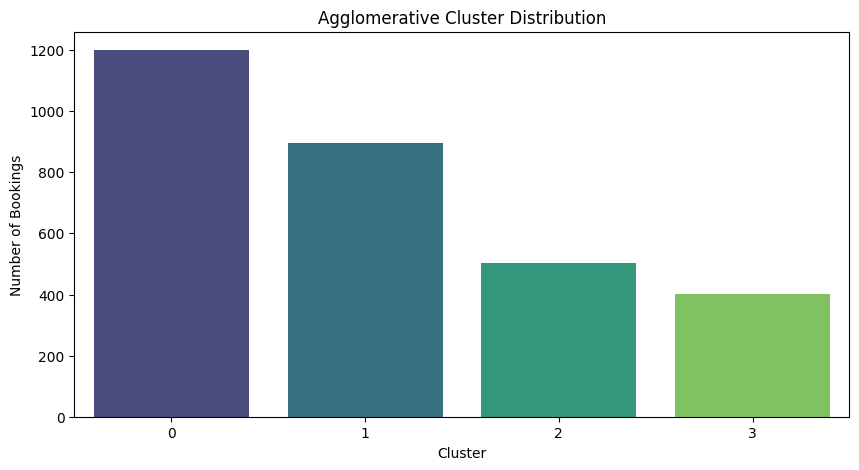

In [52]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=sample,
    x="Agg_Cluster",
    palette="viridis"
)

plt.title("Agglomerative Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Bookings")
plt.show()

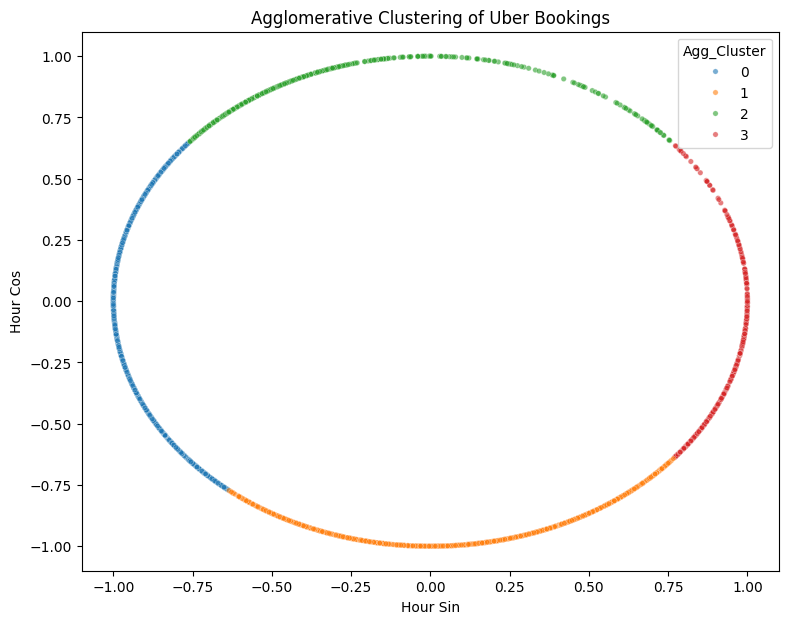

In [53]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=sample,
    x="Hour_Sin",
    y="Hour_Cos",
    hue="Agg_Cluster",
    palette="tab10",
    alpha=0.6,
    s=15
)

plt.title("Agglomerative Clustering of Uber Bookings")
plt.xlabel("Hour Sin")
plt.ylabel("Hour Cos")
plt.show()

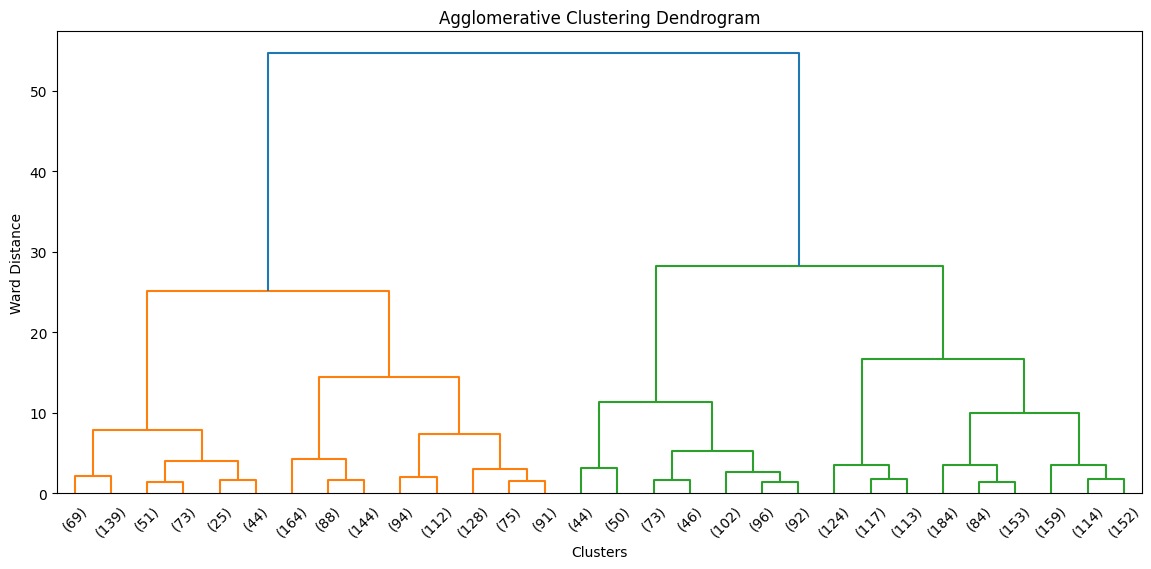

In [54]:
Z = linkage(X_sample, method="ward")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30
)

plt.title("Agglomerative Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Ward Distance")
plt.show()

In [55]:
# K-Means cluster-wise hourly distribution
print("K-MEANS HOURLY DISTRIBUTION")
print(pd.crosstab(df["KMeans_Cluster"], df["Hour"]))

# Agglomerative cluster-wise hourly distribution
print("\nAGGLOMERATIVE HOURLY DISTRIBUTION")
print(pd.crosstab(sample["Agg_Cluster"], sample["Hour"]))

# DBSCAN cluster sizes
print("\nDBSCAN LARGEST CLUSTERS")
print(df[df["DBSCAN_Cluster"] != -1]["DBSCAN_Cluster"]
      .value_counts().head(10))

K-MEANS HOURLY DISTRIBUTION
Hour              0     1     2     3     4     5     6     7     8     9   \
KMeans_Cluster                                                               
0                  0     0     0     0     0     0     0     0     0     0   
1                  0     0     0     0     0     0     0     0     0  8178   
2                  0   184  1339  1383  1321  2786  4160  5450  6861    56   
3               1373  1176     0     0     0     0     0     0     0     0   

Hour            ...    14    15    16     17     18     19    20    21    22  \
KMeans_Cluster  ...                                                            
0               ...  6979  8202  9633  11044  11313      0     0     0     0   
1               ...    52     0     0      0      0      0     0     0     0   
2               ...     0     0     0      0      0      0     0     0     0   
3               ...     0     0     0      0   1084  11047  9630  8103  5441   

Hour              23  